# 09 · Elasticsearch 查询、分页、高亮与聚合（Elasticsearch02）


## 本章来源与学习路线

依据百度网盘 `我的资源/day09-Elasticsearch02/PPT/Elasticsearch02.pptx` 整理。原 PPT 与网盘预览均为 **53 页，无隐藏页**；关键截图内嵌，可离线阅读。

| 课件范围 | 本篇知识 |
| --- | --- |
| 第 2—13 页 | DSL 结构、全文与精确查询 |
| 第 15—17 页 | 复合查询、bool 与商品筛选 |
| 第 19—27 页 | 排序、分页、深度分页、高亮 |
| 第 30—43 页 | Java 查询构造、结果解析、排序分页与高亮 |
| 第 45—53 页 | 聚合分类、桶与指标、Java 聚合 |

延续第 08 篇：**ES / IK / RestHighLevelClient 7.12.1，商品价格以分保存，Java 示例兼容 Java 8**。不把新客户端的代码混入课程客户端。来源只有 PPT，未核对到 day09 的业务源码或父 POM。

课件代码中的占位字段、JSON 注释、尾随逗号、混用索引名已整理；价格范围按“元 → 分”显式换算。标为“补充”的内容解释 should 默认值、查询完整性、PIT、聚合误差等工程边界。

学习顺序：**选择查询 → 组合筛选与评分 → 排序分页 → 高亮 → Java 构造与解析 → 聚合与页面统计**。本篇没有运行 ES、Kibana 或 Java 工程；请求与代码用于匹配版本的学习环境。


## 1. DSL 查询与搜索流程

上一章解决“数据怎样写入”，本章解决“哪些商品应该返回，怎样排列与展示”。DSL（Domain Specific Language，领域专用语言）使用 JSON 表达 ES 查询条件。（课件第 2、5—8 页）

```text
用户输入关键词与筛选条件
        ↓
选择叶子查询 → 用复合查询组合
        ↓
匹配文档并按需要评分
        ↓
排序 → 取当前页 → 返回原文档与高亮
        ↓
按匹配范围计算聚合（如果请求了聚合）
```

这表示各参数的职责，聚合不只统计当前页：它通常遍历 query 匹配的文档范围。

| 顶层参数 | 职责 |
| --- | --- |
| query | 决定匹配条件与适用的相关性评分 |
| sort | 决定结果排序 |
| from、size | 决定返回哪一页、最多几条 |
| highlight | 生成高亮片段 |
| aggs / aggregations | 计算分组与统计 |
| _source | 控制返回哪些原始文档字段 |
| track_total_hits | 控制匹配文档总数的追踪方式 |

Kibana Console 支持 `GET /items/_search` 携带请求体；应用也可通过 POST 或 Java 客户端发请求。普通查询应明确指定索引，避免无意中搜索全部索引。


## 2. 查询前先确认 Mapping 与单位

同样的字符串，放在 text 和 keyword 字段中会产生不同的查询语义；查询失败首先检查字段定义。（承接第 08 篇）

| items 字段 | 类型 / 约定 | 本章用途 |
| --- | --- | --- |
| name | text，写入 ik_max_word，搜索 ik_smart | 全文检索与高亮 |
| id | keyword，字符串 | 精确匹配、稳定排序；与 `_id` 按业务约定一致 |
| brand、category | keyword | 精确筛选与 terms 聚合 |
| price | integer，单位分 | 价格范围、排序、价格统计 |
| sold、commentCount | integer | 排序或统计 |
| isAD | boolean | 广告标记、可选排名策略 |
| updateTime | date | 日期范围或日期聚合 |
| stock、image | 上篇整理方案为 index:false、doc_values:false | 从 `_source` 展示，不用于本章筛选 / 排序 / 聚合 |

```http
GET /items/_mapping
```

查询 name 时可先观察分词：

```http
POST /items/_analyze
{
  "field": "name",
  "text": "脱脂牛奶"
}
```

数值 30000 表示 300 元，而不是 30000 元。HTTP 和 Java 示例都使用分；页面输入元时在接口边界转换一次，避免漏转换或重复乘 100。


## 3. match_all 与搜索响应

`match_all` 匹配所有文档，可用于验证索引数据、排序和分页。它不会把全部商品一次性返回，默认一页最多 10 条。（课件第 8、30—32 页）

```http
GET /items/_search
{
  "query": {
    "match_all": {}
  },
  "size": 10
}
```

下面是**响应结构示例，不代表实际执行结果**：

```json
{
  "took": 3,
  "timed_out": false,
  "_shards": {
    "total": 1,
    "successful": 1,
    "skipped": 0,
    "failed": 0
  },
  "hits": {
    "total": {
      "value": 1,
      "relation": "eq"
    },
    "max_score": 1.0,
    "hits": [
      {
        "_index": "items",
        "_id": "1001",
        "_score": 1.0,
        "_source": {
          "id": "1001",
          "name": "小米手机",
          "price": 349900
        }
      }
    ]
  }
}
```

| 响应路径 | 含义 |
| --- | --- |
| took | ES 服务端处理耗时，单位毫秒，不是完整网络往返时间 |
| timed_out | 是否在完成前超时；true 时可能只返回部分结果 |
| _shards | 分片执行情况，需关注失败 |
| hits.total | 匹配总数及精确 / 下界关系 |
| hits.hits | 本次返回的文档数组 |
| hits.hits[i]._source | 该文档返回的原始业务字段 |
| hits.hits[i]._score | 相关性分数，某些排序下不计算或返回 null |

外层 hits 是结果容器，内层 hits 是当前页数组。数组长度、匹配总数和索引全部文档数是三个不同数字。


## 4. match 全文查询

用户输入“智能手机”时，通常希望命中相关名称，而非要求名称完整等于这四个字。match 根据字段的分析器分析输入，再查询词条。（课件第 10—13 页）

```http
GET /items/_search
{
  "query": {
    "match": {
      "name": "智能手机"
    }
  }
}
```

默认 match 常用 OR 组合分析后的词条。若实际分析得到“智能”“手机”，命中任一词即可进入候选集；想要求两词都命中，可指定 AND：

```http
GET /items/_search
{
  "query": {
    "match": {
      "name": {
        "query": "智能手机",
        "operator": "and"
      }
    }
  }
}
```

AND 不保证词语紧邻、顺序一致，也不保证完整名称相等。需要短语语义时评估 `match_phrase`（补充）；需要精确字段值时选 keyword + term。

相关性 `_score` 衡量文本匹配程度。它受词频、词条稀有程度、字段长度等因素影响，不能理解为价格、销量或固定的“匹配字数”。


## 5. multi_match 与多字段语义

同一个搜索词需要在多个字段中查找时，用 multi_match。（课件第 11、13、35 页）

**按课件字段整理**：

```http
GET /items/_search
{
  "query": {
    "multi_match": {
      "query": "脱脂牛奶",
      "fields": ["name", "category"]
    }
  }
}
```

| 查询 | 字段范围 | 选择 |
| --- | --- | --- |
| match | 一个字段 | 商品名称搜索 |
| multi_match | 多个字段 | 标题、描述等多字段全文搜索 |
| term | 精确值字段 | 分类、品牌筛选 |

multi_match 会遵循每个字段各自的类型与分析方式。上篇 category 是 keyword，所以“脱脂牛奶”通常作为完整值对 category 查询，**不会自动拆成“脱脂”“牛奶”并匹配分类“牛奶”**。业务意图若是“名称含脱脂牛奶、分类必须为牛奶”，应使用 match + term 的 bool 组合。

补充：`fields: ["name^2", "description"]` 可以提高 name 的权重，前提是已有 description Mapping。字段越多通常增加查询工作量，但性能还取决于类型、分析器和数据量，不能直接推断成固定的下降比例。


## 6. term、terms 与 ids

精确查询直接使用给定的词条或精确值，不像 match 一样对用户输入做全文分词。（课件第 10—13、36 页）

**品牌完整等于华为**：

```http
GET /items/_search
{
  "query": {
    "term": {
      "brand": {
        "value": "华为"
      }
    }
  }
}
```

**补充：品牌是华为或小米**：

```http
GET /items/_search
{
  "query": {
    "terms": {
      "brand": ["华为", "小米"]
    }
  }
}
```

**根据 ES 文档 ID 查询**：

```http
GET /items/_search
{
  "query": {
    "ids": {
      "values": ["1001", "1002"]
    }
  }
}
```

term 匹配单个值；terms 匹配给定值集合中的任一值；ids 查 `_id`，不查询 `_source.id`。`term: {"id": "1001"}` 则查普通业务 id 字段。

> term 仍可匹配 text 字段中已有的词条，但不会分析输入。直接用完整商品名称查询 text，往往与实际索引词条不一致。因此完整品牌、分类、状态等筛选优先映射成适合精确查询的类型。

DSL 键名是 `match`、`multi_match` 等；课件分类页的 match_query / multi_match_query 是表述，不能直接当作请求里的查询类型键。


## 7. range、价格与日期边界

range 用于数值或日期的区间查询。（课件第 12—13、17、36—38 页）

| 运算符 | 含义 |
| --- | --- |
| gt | 大于，不含边界 |
| gte | 大于或等于 |
| lt | 小于，不含边界 |
| lte | 小于或等于 |

价格低于 300 元：

```http
GET /items/_search
{
  "query": {
    "range": {
      "price": {
        "lt": 30000
      }
    }
  }
}
```

| 页面条件 | 分为单位的条件 |
| --- | --- |
| 低于 300 元 | `lt: 30000` |
| 不高于 300 元 | `lte: 30000` |
| 高于 3000 元 | `gt: 300000` |
| 900 元至 1599 元，字面闭区间 | `gte: 90000, lte: 159900` |
| 页面档位 900—1599 元，包含 1599.99 元 | `gte: 90000, lt: 160000` |

档位划分适合半开区间，相邻档位不会重叠；按需求确认上边界到底是 1599.00 还是 1600.00 之前。

补充：查询上海时间 2026-10-09 更新的商品，用次日零点作为不包含的上界：

```http
GET /items/_search
{
  "query": {
    "range": {
      "updateTime": {
        "gte": "2026-10-09T00:00:00+08:00",
        "lt": "2026-10-10T00:00:00+08:00"
      }
    }
  }
}
```

带偏移的日期说明实际时间；不要给上海本地时间直接加 Z。字段必须是 date，字符串格式应符合 Mapping。


## 8. 地理查询与 Mapping 前提

附近门店、酒店等数据包含坐标时，可按距离或矩形区域筛选。（课件第 10 页，仅列举；下列为补充示例）

| 查询 | 用途 |
| --- | --- |
| geo_distance | 距离某点指定半径以内 |
| geo_bounding_box | 落在指定经纬度矩形内 |

本章 items 没有地理字段。下面假设**另一个** `stores` 索引已经把 location 映射为 `geo_point`：

```json
{
  "mappings": {
    "properties": {
      "location": {
        "type": "geo_point"
      }
    }
  }
}
```

```http
GET /stores/_search
{
  "query": {
    "geo_distance": {
      "distance": "5km",
      "location": {
        "lat": 31.2304,
        "lon": 121.4737
      }
    }
  }
}
```

```http
GET /stores/_search
{
  "query": {
    "geo_bounding_box": {
      "location": {
        "top_left": {
          "lat": 31.3,
          "lon": 121.4
        },
        "bottom_right": {
          "lat": 31.2,
          "lon": 121.5
        }
      }
    }
  }
}
```

lat 是纬度，lon 是经度；ES 的坐标数组写法是 `[lon, lat]`。不能把普通字符串地址直接交给地理查询，必须先取得坐标并建立相应 Mapping。


## 9. bool 与查询 / 过滤上下文

关键词、品牌、价格通常同时存在。bool 把叶子查询组合成逻辑条件，并决定子查询是否参与相关性评分。（课件第 15—16、37 页）

| 子句 | 匹配约束 | 通常是否贡献 `_score` |
| --- | --- | --- |
| must | 每个子句都必须匹配 | 是 |
| filter | 每个子句都必须匹配 | 否 |
| must_not | 对每个子句都要求不匹配 | 否 |
| should | 按 minimum_should_match 决定至少命中几个 | 在查询上下文中可贡献 |

```text
must：名称匹配“手机” → 决定匹配与相关程度
filter：品牌、价格 → 判断是否符合条件
must_not：排除条件 → 剔除不允许的商品
should：偏好条件 → 可用于加分，也可明确要求至少命中一个
```

只关心品牌与价格是否满足时，放进 filter；需要根据关键词匹配程度排名时，放进 must。filter 子句不计算相关性分数，并可能被缓存；不能理解成每种 filter 都必然缓存或一定比所有查询更快。

只有 filter 的 bool 查询没有关键词相关性排序基础，通常分数为 0；此时应按价格、销量等明确排序。同一布尔条件放在不同上下文，计分行为可能变化。


## 10. should 的默认值与显式 OR

课件用“类似或”解释 should，实际还要看 minimum_should_match。（课件第 16 页；默认规则按 ES 7.12 文档补充）

| 同一个 bool 的结构 | 默认 minimum_should_match |
| --- | --- |
| 有 should，但没有 must 和 filter | 1 |
| 有 must 或 filter | 0 |

存在 must / filter 时，should 默认**不要求命中**，通常用来增加匹配偏好的分数。课件“名称含手机 + should 品牌 vivo / 小米”的示例不能理解成“只允许这两个品牌”。

想要求名称匹配手机，且品牌必须命中华为 / 小米其中之一：

```http
GET /items/_search
{
  "query": {
    "bool": {
      "must": [
        {"match": {"name": "手机"}}
      ],
      "should": [
        {"term": {"brand": "华为"}},
        {"term": {"brand": "小米"}}
      ],
      "minimum_should_match": 1
    }
  }
}
```

若品牌只用于硬筛选、不希望品牌影响评分，更直接的写法是将 `terms: {"brand": ["华为", "小米"]}` 放入 filter。

多个“至少满足一个”的条件组可以分别放进嵌套 bool，并为每组显式设置 minimum_should_match。不要靠外层默认值猜整个请求的 OR 语义。


## 11. 商品筛选案例

需求：搜索“智能手机”，品牌必须是华为，价格在 900—1599 元。（课件第 17 页）

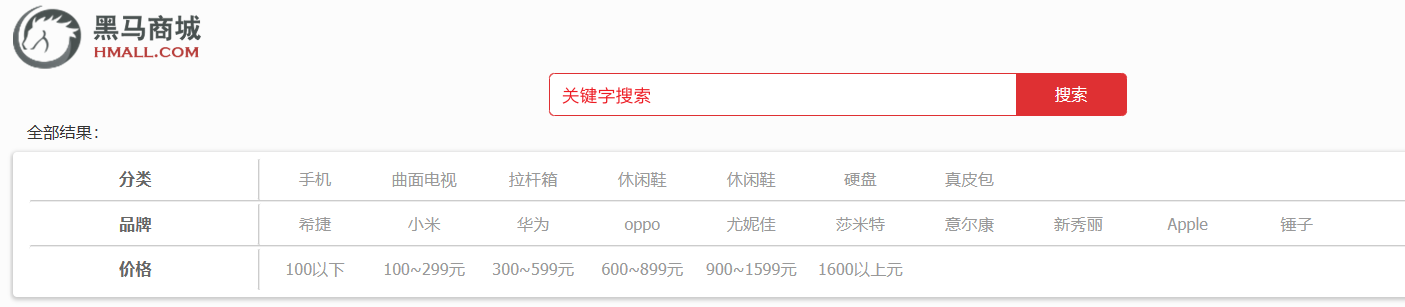

按**字面闭区间 900.00—1599.00 元**整理：

```http
GET /items/_search
{
  "query": {
    "bool": {
      "must": [
        {
          "match": {
            "name": {
              "query": "智能手机",
              "operator": "and"
            }
          }
        }
      ],
      "filter": [
        {"term": {"brand": "华为"}},
        {"range": {"price": {"gte": 90000, "lte": 159900}}}
      ]
    }
  }
}
```

这里补充 AND，明确要求分析后的所有词条命中；若希望扩大召回，可采用默认 OR 并评估结果。若 UI 的价位档包含 1599.99 元，将上界改为 `lt: 160000`，不要只改页面文案。

品牌与范围只负责筛选，关键词负责相关性。把条件统一写成“全部 should”会放宽结果，不能保证品牌和价格必须符合。


## 12. 排名调整：function_score 与 dis_max

逻辑查询决定哪些文档进入候选集；另一些复合查询用于调整候选集的分数。（课件第 15 页，仅概览）

| 查询 | 作用 | 场景 |
| --- | --- | --- |
| bool | 按逻辑组合子查询，并合并适用的分数 | 关键词 + 条件筛选 |
| function_score | 根据函数或权重修改基础分数 | 在相关性基础上考虑业务权重 |
| dis_max | 主要使用最佳匹配子查询的分数，可用 tie_breaker 纳入其他分数 | 多字段中某一个强匹配即可的排名 |

例如名称匹配后，广告商品可以按受控权重参与排序；这是**排名规则**，不自动改变品牌、价格等硬筛选条件。销量与相关性之间怎样组合，也需要业务效果验证。

课件没有展开这两种查询的公式，本篇不虚构“固定排名算法”。显式按 price 排序时，价格主导排名，相关性加分不会自动把商品放到价格较低的商品前面。


## 13. 单字段与多字段排序

默认搜索通常按 `_score` 降序；页面按销量、价格排序时，应显式设置 sort。（课件第 19—20、22 页）

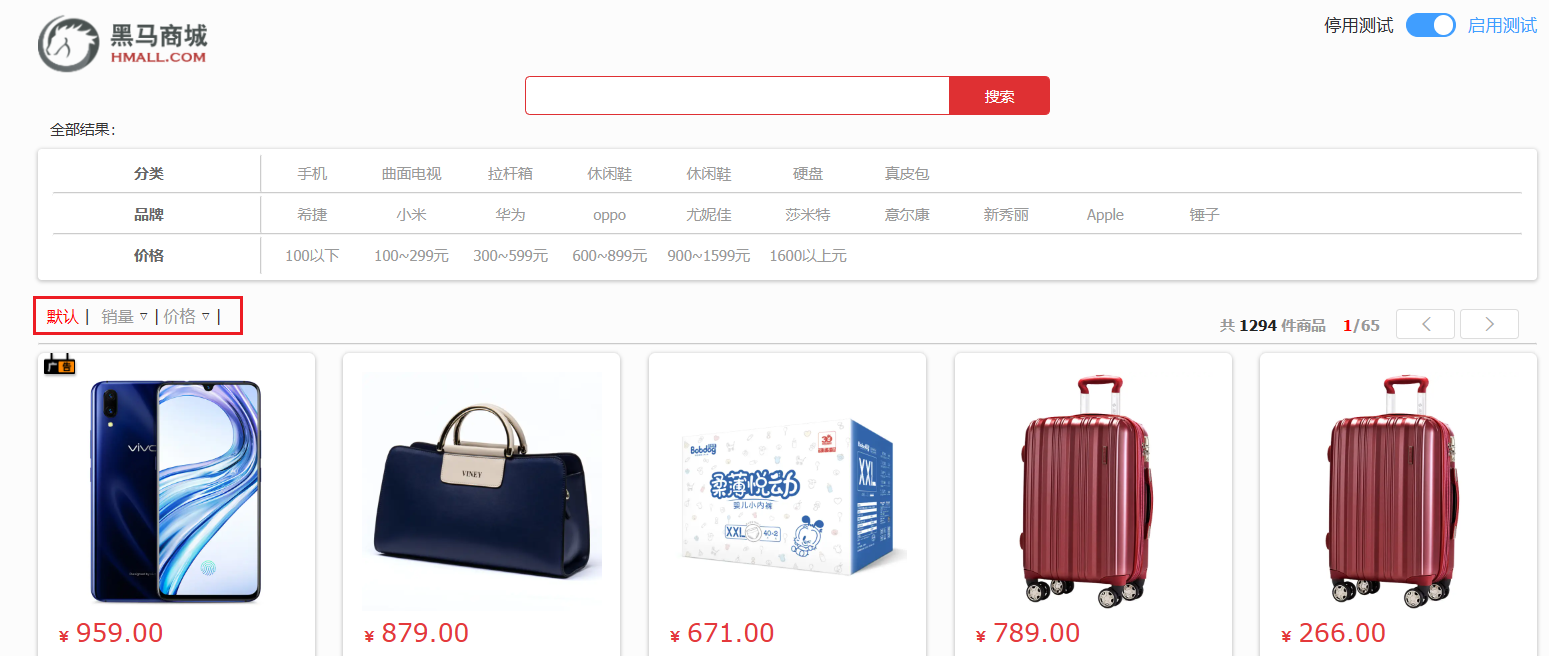

需求：销量降序，销量相同则价格升序；本篇再补充唯一商品 id 作为最终排序字段：

```http
GET /items/_search
{
  "query": {
    "match_all": {}
  },
  "sort": [
    {"sold": "desc"},
    {"price": "asc"},
    {"id": "asc"}
  ]
}
```

排序数组从前到后比较，只有前面的值相同才比较下一个。id 是 keyword，使用字符串顺序；它作为唯一值可稳定打破销量与价格相同的并列。

keyword、数值、date 等字段通常通过 doc_values 排序。text 不适合直接做名称排序，若业务需要，应设计对应的 keyword 多字段。geo_point 可用专门的地理距离排序，不能当作一个普通数值直接排序。

不要直接拿 `_id` 当常规排序字段；上篇已保存有 doc_values 的业务 id，可以用它打破并列。显式字段排序下 `_score` 可能为 null；需要读取分数时再评估 `track_scores`（补充），它不会改变已选的主排序规则。


## 14. from、size 与 total

from 表示跳过多少条匹配结果，size 表示本页最多返回多少条。（课件第 21—22 页）

```text
pageNo 从 1 开始：
from = (pageNo - 1) × pageSize

第 1 页，每页 10 条：from=0
第 2 页，每页 10 条：from=10
第 100 页，每页 10 条：from=990
```

```http
GET /items/_search
{
  "query": {
    "match_all": {}
  },
  "from": 10,
  "size": 10,
  "sort": [
    {"sold": "desc"},
    {"price": "asc"},
    {"id": "asc"}
  ],
  "track_total_hits": true
}
```

`size` 不是总条数，也不保证一定返回指定数量；最后一页可能少于 10 条。

ES 7.12 默认精确追踪总数到 10000 的阈值。读取 total 必须同时看 relation：`eq` 表示精确值，`gte` 表示至少这么多，不能把下界直接用作精确总页数。需要精确总数时设 `track_total_hits: true`，会增加部分查询工作；设 false 则不返回总数。

**10000 的总数追踪阈值**与**10000 的默认分页窗口**是两项不同设置。前者影响 total 的精确性，后者限制 from + size。


## 15. 深度分页的成本

分片各自只有局部排序信息，协调节点必须收集足够的候选结果才能确定全局第几名。（课件第 23—24 页）

```text
第 100 页，每页 10 条：from + size = 1000

分片 1：提交局部前 1000 个候选
分片 2：提交局部前 1000 个候选
分片 3：提交局部前 1000 个候选
分片 4：提交局部前 1000 个候选
                 ↓
协调节点合并排序 → 全局前 1000 → 只返回第 991—1000 名
```

这是成本的教学模型，不能理解成每个分片都会把前 1000 条的完整 `_source` 全部发送给前端。代价主要包括候选收集、排序、传输与协调内存，最后再获取当前页需要的文档内容。

默认 `index.max_result_window` 通常为 10000，普通分页要求 from + size 不超窗口。直接把窗口调大不会消除深分页成本。

| 方式 | 适用范围 | 主要边界 |
| --- | --- | --- |
| from + size | 浅分页、页码式跳转 | 深页成本高，受窗口限制 |
| search_after | 连续向后翻页、滚动列表、遍历 | 需要上一页排序值，不能直接随机跳到任意页 |
| search_after + PIT | 多页间保持相同索引视图 | 保持上下文有资源与有效期成本 |
| scroll | 旧式批量遍历流程 | 不适合普通实时用户分页，使用后清理上下文 |

列表接口应限制页大小和访问深度；大规模导出或迁移采用连续遍历，而非不断扩大 from。


## 16. search_after 的排序游标

search_after 从上一页最后一条文档的**排序值**之后继续查询，不需要跳过所有前页结果。（课件第 24 页；请求补充）

第一页：

```http
GET /items/_search
{
  "query": {
    "match_all": {}
  },
  "size": 10,
  "sort": [
    {"sold": "desc"},
    {"price": "asc"},
    {"id": "asc"}
  ]
}
```

假设最后一条返回 `"sort": [1200, 3500, "1001"]`，下一页使用这一数组：

```http
GET /items/_search
{
  "query": {
    "match_all": {}
  },
  "size": 10,
  "sort": [
    {"sold": "desc"},
    {"price": "asc"},
    {"id": "asc"}
  ],
  "search_after": [1200, 3500, "1001"]
}
```

示例排序值是假设值；实际必须原样使用上一页最后一个 hit 的 sort 数组，保持顺序和数值 / 字符串类型。Java 可从 `hit.getSortValues()` 取得，再传给 `request.source().searchAfter(...)`。

query 与 sort 在连续页间保持相同，from 省略或用 0；不能每页修改筛选、改排序后沿用旧游标。最终唯一排序值可以减少并列导致的重复或遗漏，但**不冻结数据**：刷新和更新仍可能改变跨页顺序，需要稳定视图时加 PIT。

课件“没有查询上限”应理解成可越过默认 from / size 窗口，不代表没有请求大小、集群资源、游标寿命或业务限制。


## 17. PIT 保持分页视图

价格和销量在翻页过程中改变，即使有唯一排序字段，也可能出现跨页遗漏或重复。PIT（Point In Time，时间点视图）保留分页期间使用的索引状态。（补充，ES 7.12 已支持）

先打开 PIT：

```http
POST /items/_pit?keep_alive=1m
```

保存响应中的真实 id。使用 PIT 搜索时，请求路径为 `/_search`，不再带 items：

```http
GET /_search
{
  "pit": {
    "id": "<打开PIT返回的ID>",
    "keep_alive": "1m"
  },
  "query": {
    "match_all": {}
  },
  "size": 10,
  "sort": [
    {"price": "asc"},
    {"_shard_doc": "asc"}
  ]
}
```

`_shard_doc` 在同一 PIT 中提供稳定的并列打破值。PIT 查询会隐式加入该排序项，本例显式写出，便于对照排序数组。

假设上一页最后一项 sort 为 `[3500, 4294967298]`，下一页：

```http
GET /_search
{
  "pit": {
    "id": "<上一响应返回的最新PIT_ID>",
    "keep_alive": "1m"
  },
  "query": {
    "match_all": {}
  },
  "size": 10,
  "sort": [
    {"price": "asc"},
    {"_shard_doc": "asc"}
  ],
  "search_after": [3500, 4294967298]
}
```

结束后关闭：

```http
DELETE /_pit
{
  "id": "<最新PIT_ID>"
}
```

尖括号字符串是明确占位，必须替换真实值；排序数组同样来自实际响应。连续页保持 query / sort，采用返回的**最新 PIT ID**，并按需要延长 keep_alive。

PIT 是对索引视图的保留，不是把全部商品复制到内存，也不是交易快照或跨系统一致性保证。长期保留会占用段文件与相关资源；到期后不能把旧 PIT 游标直接当作新 PIT 的继续位置。


## 18. scroll 的机制与适用范围

课件介绍 scroll 作为深分页方案，同时说明官方已不推荐用它做深分页。（课件第 24 页）

scroll 保留搜索上下文，使后续批次看到首次请求时的匹配视图；返回 `_scroll_id`，下一次用最新 scroll ID 取下一批，直到 hits 数组为空。

它仍常见于旧系统的批量读取、迁移代码。ES 7.12 官方建议需要保持索引视图的深分页采用 **search_after + PIT**；普通用户页码查询不适合长期持有 scroll。

课件“排序数据形成快照，保存在内存”的表述过于简单：上下文会保留搜索状态和所需索引段，存在堆、磁盘、文件句柄等成本，并非一次性把全部排序结果复制进内存。

批处理使用 scroll 时，应控制批量、keep_alive 和并发，用最新返回的 scroll ID，并在结束或异常退出时清理。业务选择已有可靠的 scroll 遍历流程，也应理解其成本后再决定是否迁移。


## 19. 高亮与原始字段

高亮把匹配词包上标记，便于用户知道为什么这条结果命中。（课件第 26—27、42—43 页）

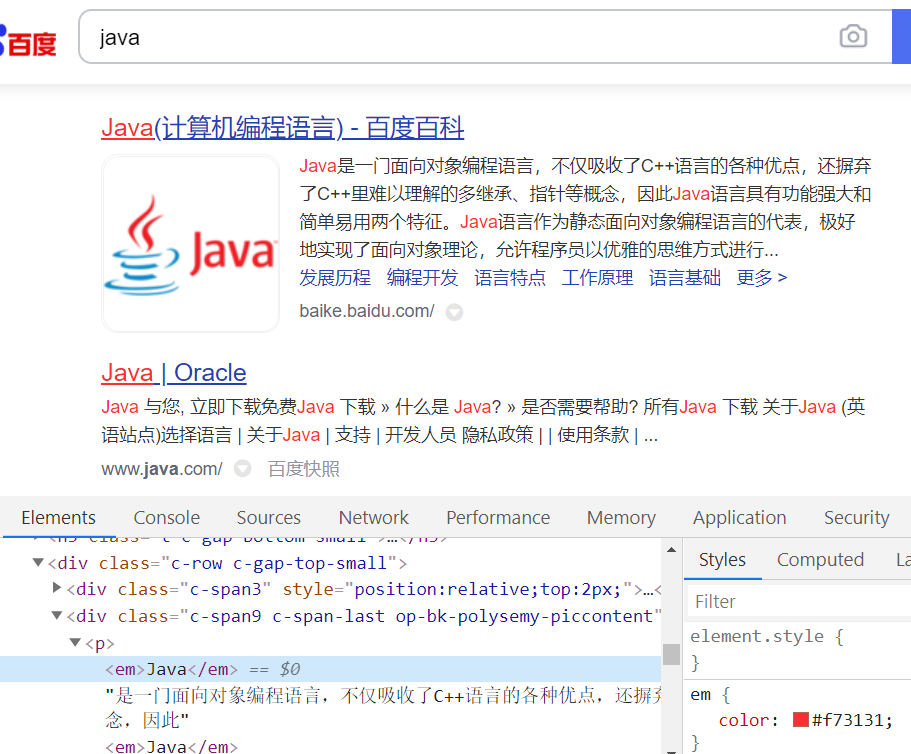

**整理示例**：pre_tags / post_tags 使用数组；商品标题设置 number_of_fragments=0，返回整段字段，而非截取摘要。

```http
GET /items/_search
{
  "query": {
    "match": {
      "name": "脱脂牛奶"
    }
  },
  "highlight": {
    "fields": {
      "name": {
        "pre_tags": ["<em>"],
        "post_tags": ["</em>"],
        "number_of_fragments": 0
      }
    }
  }
}
```

某个 hit 的结构示例：

```json
{
  "_source": {
    "name": "安佳脱脂牛奶"
  },
  "highlight": {
    "name": ["安佳<em>脱脂</em><em>牛奶</em>"]
  }
}
```

`_source.name` 保持原文，高亮出现在单独的 highlight 中，并不改写索引。高亮字段可能缺失、数组可能为空；返回展示对象时保留原名称作为回退。

长描述可以使用多个摘要片段，商品短标题可返回完整字段。高亮受分析器、查询和高亮器行为影响，不应作为命中条件正确性的替代证据。前端渲染应保留受控标记并安全处理原文，避免把任意商品文本当作可信 HTML。


## 20. 完整 REST 商品查询

把关键词、品牌、价格、分页、销量排序和高亮放进一个请求。（课件第 27、38 页需求的组合整理）

需求：名称匹配“脱脂牛奶”，品牌德亚，低于 300 元；每页 5 条，查询第 2 页；销量高的先返回，同销量按低价排序。

```http
GET /items/_search
{
  "query": {
    "bool": {
      "must": [
        {
          "match": {
            "name": {
              "query": "脱脂牛奶",
              "operator": "and"
            }
          }
        }
      ],
      "filter": [
        {"term": {"brand": "德亚"}},
        {"range": {"price": {"lt": 30000}}}
      ]
    }
  },
  "from": 5,
  "size": 5,
  "sort": [
    {"sold": "desc"},
    {"price": "asc"},
    {"id": "asc"}
  ],
  "track_total_hits": true,
  "highlight": {
    "fields": {
      "name": {
        "pre_tags": ["<em>"],
        "post_tags": ["</em>"],
        "number_of_fragments": 0
      }
    }
  }
}
```

关键词参与匹配；品牌和金额是硬约束；sort 决定最终展示顺序。匹配为空时返回空数组，不代表 DSL 错误。先分别验证 match、term、range，再组合，能够定位是词条、字段值还是金额单位造成无结果。


## 21. Java 查询对象与 QueryBuilders

课程仍使用第 08 篇的 RestHighLevelClient 7.12.1。已有客户端与依赖时，本章不重复初始化；Java API 把 DSL 构造成对象。（课件第 30—37 页）

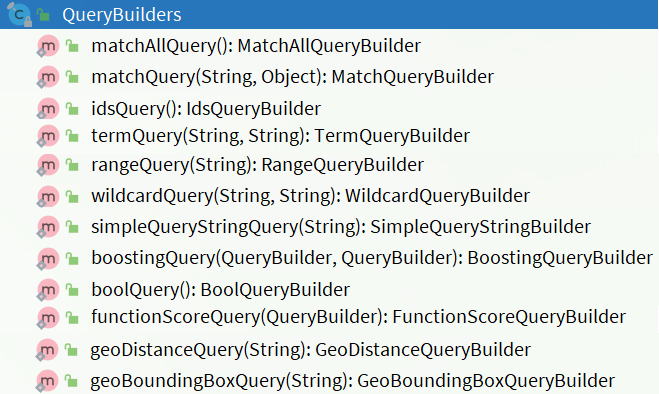

| 对象 / 方法 | 对应职责 |
| --- | --- |
| SearchRequest | 搜索哪个索引及请求选项 |
| SearchSourceBuilder | query、sort、from、size、highlight、aggs 等请求体 |
| QueryBuilders | 构建叶子 / 复合查询 |
| `client.search(request, RequestOptions.DEFAULT)` | 发起搜索 |
| SearchResponse | 响应入口 |
| SearchHits / SearchHit | 总数信息 / 当前页的每条结果 |

以下为**方法体内的构造片段**，imports 放到文件头：

```java
import org.elasticsearch.index.query.BoolQueryBuilder;
import org.elasticsearch.index.query.Operator;
import org.elasticsearch.index.query.QueryBuilder;
import org.elasticsearch.index.query.QueryBuilders;

QueryBuilder all = QueryBuilders.matchAllQuery();
QueryBuilder match = QueryBuilders.matchQuery("name", "脱脂牛奶")
    .operator(Operator.AND);
QueryBuilder multi = QueryBuilders.multiMatchQuery(
    "脱脂牛奶", "name", "category"
);
QueryBuilder term = QueryBuilders.termQuery("category", "牛奶");
QueryBuilder ids = QueryBuilders.idsQuery().addIds("1001", "1002");
QueryBuilder range = QueryBuilders.rangeQuery("price").lt(30000);

BoolQueryBuilder bool = QueryBuilders.boolQuery()
    .must(QueryBuilders.matchQuery("name", "脱脂牛奶"))
    .filter(QueryBuilders.termQuery("brand", "德亚"))
    .filter(QueryBuilders.rangeQuery("price").lt(30000));
```

先构造查询，再传给 `source.query(...)`。不要反复调用 query 想“累加”条件：后设置的顶层 query 会替换前面的，多个约束应合并进 bool。

QueryBuilders 的 matchQuery 对应 DSL 的 match，multiMatchQuery 对应 multi_match。新 Java API Client 的包名与构造方式不同，不能只替换依赖而保留这些调用。


## 22. Java 构造完整查询并发送

下面对应第 20 节，查询脱脂牛奶、德亚品牌、低于 300 元；包含排序、分页、完整标题高亮。（课件第 38、40、42 页整理）

```java
import java.io.IOException;
import org.elasticsearch.action.search.SearchRequest;
import org.elasticsearch.action.search.SearchResponse;
import org.elasticsearch.client.RequestOptions;
import org.elasticsearch.client.RestHighLevelClient;
import org.elasticsearch.index.query.BoolQueryBuilder;
import org.elasticsearch.index.query.Operator;
import org.elasticsearch.index.query.QueryBuilders;
import org.elasticsearch.search.builder.SearchSourceBuilder;
import org.elasticsearch.search.fetch.subphase.highlight.HighlightBuilder;
import org.elasticsearch.search.sort.SortOrder;

public class ItemSearchExample {
    public static SearchRequest build(int pageNo, int pageSize) {
        if (pageNo < 1 || pageSize < 1 || pageSize > 100) {
            throw new IllegalArgumentException("分页参数不合法");
        }
        long offset = (pageNo - 1L) * pageSize;
        if (offset + pageSize > 10000L) {
            throw new IllegalArgumentException("超出本示例默认分页窗口");
        }

        BoolQueryBuilder query = QueryBuilders.boolQuery()
            .must(QueryBuilders.matchQuery("name", "脱脂牛奶")
                .operator(Operator.AND))
            .filter(QueryBuilders.termQuery("brand", "德亚"))
            .filter(QueryBuilders.rangeQuery("price").lt(30000));

        HighlightBuilder highlight = new HighlightBuilder()
            .field(new HighlightBuilder.Field("name")
                .numOfFragments(0))
            .preTags("<em>")
            .postTags("</em>");

        SearchSourceBuilder source = new SearchSourceBuilder()
            .query(query)
            .from((int) offset)
            .size(pageSize)
            .sort("sold", SortOrder.DESC)
            .sort("price", SortOrder.ASC)
            .sort("id", SortOrder.ASC)
            .trackTotalHits(true)
            .highlighter(highlight);

        return new SearchRequest("items").source(source);
    }

    public static SearchResponse search(RestHighLevelClient client,
                                         int pageNo, int pageSize)
            throws IOException {
        return client.search(build(pageNo, pageSize), RequestOptions.DEFAULT);
    }
}
```

调用 `search(client, 2, 5)` 即第 2 页、每页 5 条。100 的页大小限制与 10000 的窗口校验是本篇整理的入口保护；实际按业务限制与索引设置配置，不能当作 ES 所有场景的固定参数。

所有排序都追加在同一个 SearchSourceBuilder，保持 sold、price、id 的顺序。高亮的 `numOfFragments(0)` 对应 REST 的 `number_of_fragments: 0`。

把固定需求改成接口参数时，后端应控制允许的字段与排序方式，并明确空关键词是查全部还是拒绝查询；不能直接让页面提交任意字段名或无限 size。


## 23. Java 解析总数、原文与高亮

响应解析沿 JSON 结构由外到内：SearchResponse → SearchHits → SearchHit → _source / highlight。（课件第 31、43 页）

课件用 JSONUtil 转 ItemDoc，再把首个高亮片段设置到 name。下面用 Map 避免依赖未提供的 DTO，并保留原始 name，将展示值放到 `nameHighlight`；同时补充空片段检查与 total 的 relation。

```java
import java.util.ArrayList;
import java.util.LinkedHashMap;
import java.util.List;
import java.util.Map;
import org.apache.lucene.search.TotalHits;
import org.elasticsearch.action.search.SearchResponse;
import org.elasticsearch.common.text.Text;
import org.elasticsearch.search.SearchHit;
import org.elasticsearch.search.SearchHits;
import org.elasticsearch.search.fetch.subphase.highlight.HighlightField;

public class ItemSearchResultParser {
    public static class Result {
        public final Long total;
        public final boolean totalExact;
        public final List<Map<String, Object>> items;

        public Result(Long total, boolean totalExact,
                      List<Map<String, Object>> items) {
            this.total = total;
            this.totalExact = totalExact;
            this.items = items;
        }
    }

    public static Result parse(SearchResponse response) {
        if (response.isTimedOut() || response.getFailedShards() > 0) {
            throw new IllegalStateException("搜索超时或存在失败分片");
        }

        SearchHits searchHits = response.getHits();
        TotalHits totalHits = searchHits.getTotalHits();
        Long total = totalHits == null ? null : totalHits.value;
        boolean exact = totalHits != null
            && totalHits.relation == TotalHits.Relation.EQUAL_TO;

        List<Map<String, Object>> items = new ArrayList<>();
        for (SearchHit hit : searchHits.getHits()) {
            Map<String, Object> source = hit.getSourceAsMap();
            if (source == null) {
                throw new IllegalStateException("本示例要求返回 _source");
            }
            Map<String, Object> item = new LinkedHashMap<>(source);
            item.put("nameHighlight", item.get("name"));

            Map<String, HighlightField> fields = hit.getHighlightFields();
            HighlightField nameField =
                fields == null ? null : fields.get("name");
            if (nameField != null) {
                Text[] fragments = nameField.getFragments();
                if (fragments != null && fragments.length > 0
                        && fragments[0] != null) {
                    item.put("nameHighlight", fragments[0].string());
                }
            }
            items.add(item);
        }
        return new Result(total, exact, items);
    }
}
```

total 允许 null，表示没有追踪总数；totalExact=false 不能被页面解释成精确总页数。hits 数组为空就是当前页没有结果，不必生成异常。

该解析器选择把超时 / 分片失败交给上层处理，不当作正常空列表。对完整结果有严格要求的接口还可设置 `allow_partial_search_results=false` 请求选项，并设计明确的失败或降级响应。

只需要部分字段时可使用 source filtering；它减少返回字段，不改变文档实际 Mapping。若关闭 `_source` 返回，就要改用请求的 fields 等结果结构，不能继续按上述方法解析。


## 24. 聚合的三种职责

搜索返回具体商品，聚合回答“有多少商品、有哪些品牌、价格分布如何”。它通常针对 query 匹配范围，而非当前页 hits。（课件第 45 页）

| 类型 | 作用 | 课件列举 |
| --- | --- | --- |
| Bucket，桶聚合 | 把文档按条件或字段分组 | terms、date_histogram |
| Metric，指标聚合 | 对字段值求统计量 | avg、min、max、stats |
| Pipeline，管道聚合 | 在其他聚合的结果上继续计算 | 如对每月均价再次求平均；请求为本篇补充 |

品牌 terms 聚合里的桶表示同一品牌的文档组；`doc_count` 是文档数量，不是商品的库存数量，也不是 sold 销量总和。要统计销量总和应对 sold 做 sum。

适合按原始类别分组的字段通常是 keyword；数值、日期等按所选聚合类型处理。课件“只能对 keyword、数值、日期、布尔字段聚合”是入门经验，并非覆盖所有聚合的严格规则：地理、过滤、管道等有各自输入要求。

text 默认不适合直接按原始名称分组。开启 fielddata 会增加内存成本，且得到的是分析后的词条；需要完整值分组时优先设计 keyword 字段。


## 25. terms 分组与两种 size

需求：统计商品有哪些分类，按 category 分组。（课件第 47 页）

```http
GET /items/_search
{
  "size": 0,
  "aggs": {
    "cateAgg": {
      "terms": {
        "field": "category",
        "size": 20
      }
    }
  }
}
```

| 参数位置 | 意义 |
| --- | --- |
| 顶层 `size: 0` | 不返回文档 hits 数组中的商品，仍计算请求的聚合 |
| `terms.size: 20` | 最多返回 20 个分类桶 |
| cateAgg | 自定义聚合名称，解析时按这个名称取得结果 |
| terms | 聚合类型，按字段精确值分组 |
| field: category | 聚合字段，需符合 Mapping |

query 可以省略，此时普通请求的范围相当于全部可见文档。默认 terms 返回**按 doc_count 降序的前 10 个桶**，并不自动返回所有不同值。

terms 是聚合类型；term 是查询类型。`size: 0` 也不表示没有扫描工作或没有 total，只表示不返回商品列表。普通字段分组示例需要名称、类型、字段三部分；管道等其他聚合不一定提供 field。


## 26. query 决定聚合范围

需求：价格高于 3000 元的手机有哪些品牌。（课件第 48 页）

```http
GET /items/_search
{
  "query": {
    "bool": {
      "filter": [
        {"term": {"category": "手机"}},
        {"range": {"price": {"gt": 300000}}}
      ]
    }
  },
  "size": 0,
  "aggs": {
    "brand_agg": {
      "terms": {
        "field": "brand",
        "size": 20
      }
    }
  }
}
```

query 与 aggs 同级：query 先限定符合业务条件的文档范围，brand_agg 再在该范围内分组。from / size 改变返回文档页，不把聚合范围缩小到这一页。

课件文字是“高于 3000 元”，代码写 gte:300000，实际包含恰好 3000 元。本篇按字面需求改成 **gt:300000**；若业务要求“不低于 3000 元”，再用 gte。

品牌桶的 doc_count 表示该品牌符合“手机且价格 > 3000 元”的文档数，不是该品牌全站商品总数。


## 27. 桶内 stats 与金额统计

需求：手机有哪些品牌，每个品牌的最低价、最高价和均价是多少。（课件第 49 页）

```http
GET /items/_search
{
  "query": {
    "term": {
      "category": "手机"
    }
  },
  "size": 0,
  "aggs": {
    "brand_agg": {
      "terms": {
        "field": "brand",
        "size": 20
      },
      "aggs": {
        "price_stats": {
          "stats": {
            "field": "price"
          }
        }
      }
    }
  }
}
```

```text
手机文档
    ↓ brand_agg 按品牌分桶
品牌 A 的文档 → price_stats
品牌 B 的文档 → price_stats
                  ↓
        count、min、max、avg、sum
```

结果结构示例：

```json
{
  "aggregations": {
    "brand_agg": {
      "buckets": [
        {
          "key": "华为",
          "doc_count": 2,
          "price_stats": {
            "count": 2,
            "min": 350000.0,
            "max": 1290000.0,
            "avg": 820000.0,
            "sum": 1640000.0
          }
        }
      ]
    }
  }
}
```

该示例均价 820000 分，即 8200 元。统计结果沿用原字段单位，不会因为 avg 返回浮点数就变成“元”。

doc_count 统计桶内文档数；stats.count 统计参与 price 统计的值数。price 缺失时两者可能不同，多值字段也可能使值数超过文档数。平均价格是商品价格的平均，并不自动按销量加权，更不是订单成交均价。

空范围可能没有桶；无有效数值的指标可能为 null 或客户端特殊空值表现，不能默认显示为 0 元。


## 28. date_histogram 与管道聚合

按月份观察商品更新时间分布，可以用 date_histogram；再处理每月聚合结果，可以用 pipeline。（课件第 45 页列举，以下为补充）

```http
GET /items/_search
{
  "size": 0,
  "aggs": {
    "by_month": {
      "date_histogram": {
        "field": "updateTime",
        "calendar_interval": "month",
        "time_zone": "Asia/Shanghai",
        "min_doc_count": 0
      },
      "aggs": {
        "avg_price": {
          "avg": {
            "field": "price"
          }
        }
      }
    },
    "avg_of_monthly_price": {
      "avg_bucket": {
        "buckets_path": "by_month>avg_price",
        "gap_policy": "skip"
      }
    }
  }
}
```

calendar_interval=month 使用日历月份，月长可以不同；固定 30 天不等于自然月。time_zone 决定分桶边界，避免把上海月底深夜误分到另一个 UTC 月份。

avg_bucket 读取每个月的 avg_price，再对有值的月份均价求平均，**每个月权重相同**。它通常不等于所有商品的整体均价；若各月商品数不同，两种统计口径会明显不同。gap_policy=skip 跳过没有有效指标的缺口。

updateTime 是当前商品文档的更新时间，不是历史交易事件时间。商品后续更新会改变所属月份；需要销售趋势时应对订单 / 交易事件建模，不能拿商品索引的更新时间推导历史销量。


## 29. 聚合排序、截断与分片误差

terms 是“前若干桶”的统计，不能把它无条件当作完整去重清单。（补充，按 ES 7.12 terms 文档）

| 参数 / 结果 | 判断 |
| --- | --- |
| terms.size | 最多返回多少桶，默认 10 |
| shard_size | 各分片提交更多候选桶；可能提高准确度，增加资源开销 |
| order | 桶的排序，默认 `_count: desc` |
| sum_other_doc_count | 没有返回的其他桶的文档计数总和 |
| doc_count_error_upper_bound | 适用排序下的计数误差上界 |
| show_term_doc_count_error | 请求每个返回桶的误差信息 |

查询的 sort 排商品；terms.order 排桶，两者不互相替代。例如品牌名称顺序可用 `order: {"_key": "asc"}`，统计热门品牌则常用默认的文档数降序。

分片提交局部候选再合并时，部分品牌可能没有被某些分片提交，文档计数和子聚合可能存在误差。增大 shard_size 是权衡，不保证所有场景都精确；误差解释还依赖桶排序，不能把所有排序下的同名字段都当作相同保证。

高基数字段表示不同值很多，例如商品 ID。一次要求大量桶会增加内存和响应成本，可能触及桶数或资源限制。需要遍历全部分类 / 多维组合时，评估 **composite 聚合的分页与 after_key**，而非把 terms.size 无限增大。

类别字段多值时，同一文档可以进入多个桶，所以桶计数之和也不一定等于匹配文档总数。


## 30. Java 构造与解析聚合

Java 聚合使用 AggregationBuilders；解析时按聚合名称取结果，再按对应类型读取。（课件第 52—53 页；stats 子聚合为整理扩展）

```java
import java.io.IOException;
import org.elasticsearch.action.search.SearchRequest;
import org.elasticsearch.action.search.SearchResponse;
import org.elasticsearch.client.RequestOptions;
import org.elasticsearch.client.RestHighLevelClient;
import org.elasticsearch.index.query.QueryBuilders;
import org.elasticsearch.search.aggregations.AggregationBuilders;
import org.elasticsearch.search.aggregations.Aggregations;
import org.elasticsearch.search.aggregations.bucket.terms.Terms;
import org.elasticsearch.search.aggregations.metrics.Stats;
import org.elasticsearch.search.builder.SearchSourceBuilder;

public class ItemAggregationExample {
    public static void printPhonePriceStats(RestHighLevelClient client)
            throws IOException {
        SearchSourceBuilder source = new SearchSourceBuilder()
            .query(QueryBuilders.termQuery("category", "手机"))
            .size(0)
            .aggregation(AggregationBuilders.terms("brand_agg")
                .field("brand")
                .size(20)
                .subAggregation(AggregationBuilders.stats("price_stats")
                    .field("price")));

        SearchResponse response = client.search(
            new SearchRequest("items").source(source),
            RequestOptions.DEFAULT
        );
        if (response.isTimedOut() || response.getFailedShards() > 0) {
            throw new IllegalStateException("聚合超时或存在失败分片");
        }

        Aggregations aggregations = response.getAggregations();
        if (aggregations == null) {
            throw new IllegalStateException("响应缺少 aggregations");
        }
        Terms brands = aggregations.get("brand_agg");
        if (brands == null) {
            throw new IllegalStateException("响应缺少 brand_agg");
        }
        for (Terms.Bucket bucket : brands.getBuckets()) {
            String brand = bucket.getKeyAsString();
            long documentCount = bucket.getDocCount();
            Stats price = bucket.getAggregations().get("price_stats");
            if (price == null || price.getCount() == 0) {
                System.out.println(brand + ": 没有有效价格");
                continue;
            }
            System.out.println(
                brand
                + ", documents=" + documentCount
                + ", minFen=" + price.getMin()
                + ", maxFen=" + price.getMax()
                + ", avgFen=" + price.getAvg()
                + ", sumFen=" + price.getSum()
            );
        }
    }
}
```

结果路径为：

```text
response.getAggregations()
    → get("brand_agg")
        → getBuckets()
            → getKeyAsString() / getDocCount()
            → bucket.getAggregations().get("price_stats")
                → getMin() / getMax() / getAvg() / getSum()
```

聚合名称必须与请求一致，类型也要一致：terms 用 Terms，stats 用 Stats。顶层 size=0，所以不从 hits 数组解析品牌选项。

输出金额标为 Fen，表示分。展示时按产品规则换算、舍入，但不能在索引侧随意改变单位。该例只解析返回的前 20 个品牌桶，仍受第 29 节的截断和分片误差边界影响。


## 31. 搜索筛选面板与 post_filter

商品列表旁的品牌、分类筛选项，可以通过聚合生成。需要先确定面板统计的是“当前所有筛选后的结果”还是“可选范围”。（工程补充）

若 query 同时限定品牌为华为，再按 brand 聚合，往往只看到华为。页面若希望选择华为后仍展示其他符合关键词的品牌，就需要让品牌面板使用更宽的统计范围。

**一种需求对应的整理示例**：query 限定名称和分类，brand 聚合展示这些结果的品牌；post_filter 再只过滤返回的商品列表。

```http
GET /items/_search
{
  "query": {
    "bool": {
      "must": [
        {"match": {"name": "手机"}}
      ],
      "filter": [
        {"term": {"category": "手机"}}
      ]
    }
  },
  "post_filter": {
    "term": {
      "brand": "华为"
    }
  },
  "size": 10,
  "aggs": {
    "brand_agg": {
      "terms": {
        "field": "brand",
        "size": 20
      }
    }
  }
}
```

post_filter 影响返回的搜索 hits，不缩小此处 query 范围内的品牌聚合。品牌桶统计“名称命中手机、分类为手机”的文档；商品列表再限定华为。

多个筛选面板可能各自需要“排除自身条件、保留其他条件”的聚合范围，需用适当的聚合 filter 设计。先明确口径再写 DSL，不能简单把所有筛选都移到 post_filter，否则所有面板都忽略了本应保留的条件。


## 32. 验证顺序与常见误读

先检查 Mapping 和 _analyze，再验证单个条件，最后检查组合、分页、高亮和聚合。以下是学习环境验证清单；本篇未执行服务端请求。

| 检查 / 现象 | 判断或处理 |
| --- | --- |
| match 结果偏宽 | 实际分词与默认 OR 是否符合需求，是否需要 AND |
| term 查询完整名称无结果 | name 是 text，输入与索引词条不一致 |
| multi_match 的 category 没命中牛奶 | keyword 保存完整值，不自动把“脱脂牛奶”拆成“牛奶” |
| 品牌 should 没命中仍返回 | must / filter 存在时默认 minimum_should_match=0 |
| 价格 300 元边界不正确 | 单位是否为分，lt 与 lte 是否混用 |
| 文档数很多但当前页只有 10 条 | 默认 size=10，区分页数组与 total |
| total.value=10000 | 还要看 relation，可能只是下界 |
| 翻页出现重复 | 排序值并列、刷新、游标类型或 PIT 视图发生变化 |
| search_after 没有下一页 | 检查上一页最后 hit 的完整 sort 数组与相同 query / sort |
| 高亮数组为空 | 允许回退原名称，不能直接取 fragments[0] |
| 聚合只有 10 个分类 | 默认 terms.size=10，不代表全站只有 10 类 |
| stats.count 与 doc_count 不同 | 缺失 / 多值字段使值数与文档数不同 |
| 聚合平均值看起来很大 | 返回值仍是分，展示再换算为元 |
| 页面换页而聚合没变 | 正常：from / size 不缩小 query 的聚合范围 |
| query 成功却数据不完整 | 检查 timed_out、分片失败、聚合截断与误差 |

建议在可控数据集对照以下边界：299.99 / 300.00 / 300.01 元；销量与价格并列；有 / 无高亮；无匹配、最后一页与空桶；should 是否明确要求命中。数据写入后还需考虑 refresh，再判断搜索是否反映新数据。

课件若干示例写的是 indexName 或 hotel，本篇商品示例统一 items；高于 3000 元示例把 gte 改为 gt；所有可复制 JSON 移除了注释和尾随逗号。stores 地理示例与 PIT 请求的特殊路径已单独注明。


## 33. 核心回顾与面试提示

| 能力 | 核心判断 |
| --- | --- |
| 选查询 | text 用 match；精确字段用 term / terms；数值日期区间用 range |
| 组合条件 | must / filter / must_not / should 各自有约束与评分语义 |
| should | 看同层 bool 的默认值，硬 OR 条件显式要求命中 |
| 排序分页 | 多字段排序需并列打破值，from / size 适合浅分页 |
| 深度分页 | search_after 使用排序游标，PIT 保持索引视图 |
| 高亮 | 单独返回片段，保留原值并检查空结果 |
| Java 查询 | SearchRequest + SearchSourceBuilder + QueryBuilders |
| 响应解析 | 总数 relation、当前页 hits、原始字段、高亮、执行完整性 |
| 聚合 | query 决定范围，顶层 size 与 terms.size 不同 |
| 统计解释 | 文档数、值数、销量、金额单位与平均口径不能混淆 |

**面试提示**：回答“match 与 term 的区别”时连接 Mapping 与分词，解释 term 不分析输入且匹配已有词条 / 精确值。回答 bool 时说明 filter 不参与相关性评分，should 的最低命中数受 must / filter 影响。回答深度分页时从各分片候选收集与协调成本解释 from + size，再说明 search_after 的稳定排序和 PIT。回答聚合时指出它不只统计当前页，terms 是前若干桶且可能有分片误差，stats 的值数与文档数不一定相同。

补充核对来源（访问日期：2026-10-09）：

- [ES 7.12：Boolean query](https://www.elastic.co/guide/en/elasticsearch/reference/7.12/query-dsl-bool-query.html)
- [ES 7.12：Paginate search results](https://www.elastic.co/guide/en/elasticsearch/reference/7.12/paginate-search-results.html)
- [ES 7.12：Search API](https://www.elastic.co/guide/en/elasticsearch/reference/7.12/search-search.html)
- [ES 7.12：Terms aggregation](https://www.elastic.co/guide/en/elasticsearch/reference/7.12/search-aggregations-bucket-terms-aggregation.html)
- [ES 7.12：Filter search results](https://www.elastic.co/guide/en/elasticsearch/reference/7.12/filter-search-results.html)
